<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/06_cnn_improved_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

tf.keras.utils.set_random_seed(42)

DATASET_DIR = "/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"

OUTPUT_DIR = os.path.dirname(DATASET_DIR)

data = np.load(os.path.join(OUTPUT_DIR, "dataset_split.npz"))

X_train = data["X_train"]
X_val = data["X_val"]
X_test = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

k_test = data["k_test"]

nama_kelas = ["TAS", "BUKU GAMBAR", "LAPTOP"]

print("DATA CNN IMPROVED BERHASIL DIBACA")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


DATA CNN IMPROVED BERHASIL DIBACA
Training: (84, 128, 128, 3)
Validation: (18, 128, 128, 3)
Testing: (18, 128, 128, 3)


In [23]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
])

print("Data augmentation berhasil disiapkan!")


Data augmentation berhasil disiapkan!


In [24]:

model_improved = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(
        32, (3, 3), padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        128, (3, 3), padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(64, activation="relu"),

    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(3, activation="softmax")
])

model_improved.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_improved.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,371 (399.89 KB)

 Trainable params: 101,923 (398.14 KB)

 Non-trainable params: 448 (1.75 KB)

In [25]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

history_improved = model_improved.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("TRAINING CNN IMPROVED SELESAI!")


Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 424ms/step - accuracy: 0.5476 - loss: 1.0624 - val_accuracy: 0.5556 - val_loss: 1.0910 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 345ms/step - accuracy: 0.7024 - loss: 0.6845 - val_accuracy: 0.3333 - val_loss: 1.1163 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 438ms/step - accuracy: 0.6548 - loss: 0.6652 - val_accuracy: 0.3333 - val_loss: 1.1179 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 455ms/step - accuracy: 0.8452 - loss: 0.4416 - val_accuracy: 0.3333 - val_loss: 1.1206 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 467ms/step - accuracy: 0.7857 - loss: 0.4605 - val_accuracy: 0.3333 - val_loss: 1.1206 - learning_rate: 5.0000e-04
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 400ms/step - accuracy: 0.8214 - loss: 0.4111 - val_accuracy: 0.3333 - val_loss: 1.1781 - learning_rate: 5.0000e-04
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 494ms/step - accuracy: 0.8333 - loss: 0

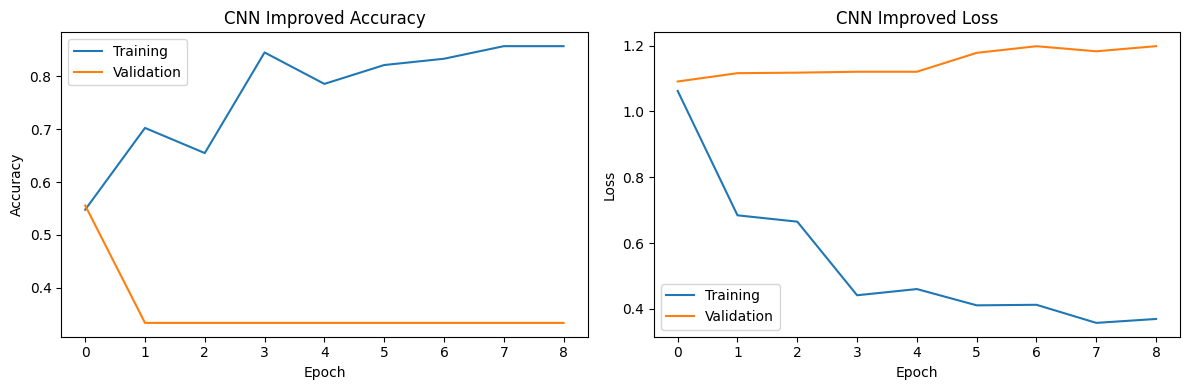

In [26]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_improved.history["accuracy"], label="Training")
plt.plot(history_improved.history["val_accuracy"], label="Validation")
plt.title("CNN Improved Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_improved.history["loss"], label="Training")
plt.plot(history_improved.history["val_loss"], label="Validation")
plt.title("CNN Improved Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [27]:

hasil_improved = model_improved.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("HASIL TESTING CNN IMPROVED")
print("Test Loss:", round(hasil_improved[0], 4))
print("Test Accuracy:", round(hasil_improved[1] * 100, 2), "%")

prediksi_improved = model_improved.predict(X_test)

pred_improved = np.argmax(prediksi_improved, axis=1)

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    pred_improved,
    labels=[0, 1, 2],
    target_names=nama_kelas,
    zero_division=0
))


HASIL TESTING CNN IMPROVED
Test Loss: 1.0977
Test Accuracy: 50.0 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 834ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         TAS       0.44      0.67      0.53         6
 BUKU GAMBAR       0.56      0.83      0.67         6
      LAPTOP       0.00      0.00      0.00         6

    accuracy                           0.50        18
   macro avg       0.33      0.50      0.40        18
weighted avg       0.33      0.50      0.40        18



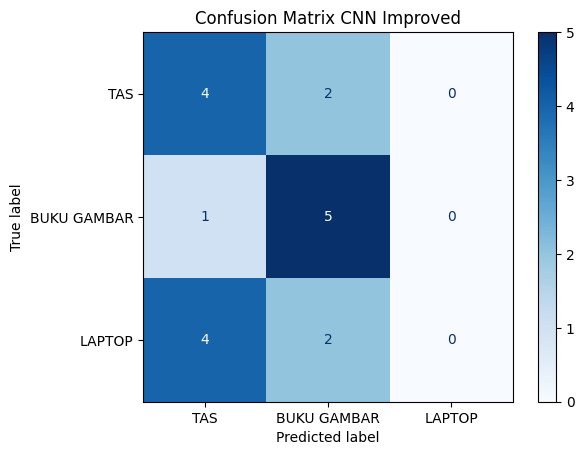

In [28]:

cm = confusion_matrix(
    y_test,
    pred_improved,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nama_kelas
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix CNN Improved")
plt.show()


In [29]:

print("EVALUASI CNN IMPROVED BERDASARKAN KONDISI")
print("=" * 45)

for kondisi in ["KONDISI IDEAL", "KONDISI SULIT"]:

    indeks = np.where(k_test == kondisi)[0]

    akurasi = accuracy_score(
        y_test[indeks],
        pred_improved[indeks]
    )

    print(kondisi)
    print("Jumlah gambar:", len(indeks))
    print("Akurasi:", round(akurasi * 100, 2), "%")
    print("-" * 45)


EVALUASI CNN IMPROVED BERDASARKAN KONDISI
KONDISI IDEAL
Jumlah gambar: 9
Akurasi: 44.44 %
---------------------------------------------
KONDISI SULIT
Jumlah gambar: 9
Akurasi: 55.56 %
---------------------------------------------


In [30]:

MODEL_FILE = os.path.join(
    OUTPUT_DIR,
    "model_cnn_improved.keras"
)

model_improved.save(MODEL_FILE)

print("MODEL CNN IMPROVED BERHASIL DISIMPAN!")
print(MODEL_FILE)


MODEL CNN IMPROVED BERHASIL DISIMPAN!
/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/model_cnn_improved.keras
